# Proyek Akhir: Menyelesaikan Permasalahan Perusahaan Edutech

- Nama: Gregorius Christian Sunaryo
- Email: christian10rks@gmail.com
- Id Dicoding: 

## Persiapan

### Menyiapkan library yang dibutuhkan

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
import pandas as pd
import numpy as np
import joblib
import sqlalchemy
import jupyter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

### Menyiapkan data yang akan diguankan

## Data Understanding

In [3]:
# Load the employee dataset from the provided URL
employee_df = pd.read_csv(
    "https://raw.githubusercontent.com/dicodingacademy/dicoding_dataset/main/employee/employee_data.csv",
    encoding='windows-1252'
)

# Display the first few rows of the dataset to understand its structure
employee_df.head()

,EmployeeId,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,1,38,NaN,Travel_Frequently,1444,Human Resources,1,4,Other,1,...,2,80,1,7,2,3,6,2,1,2
1,2,37,1.0,Travel_Rarely,1141,Research & Development,11,2,Medical,1,...,1,80,0,15,2,1,1,0,0,0
2,3,51,1.0,Travel_Rarely,1323,Research & Development,4,4,Life Sciences,1,...,3,80,3,18,2,4,10,0,2,7
3,4,42,0.0,Travel_Frequently,555,Sales,26,3,Marketing,1,...,4,80,1,23,2,4,20,4,4,8
4,5,40,NaN,Travel_Rarely,1194,Research & Development,2,4,Medical,1,...,2,80,3,20,2,3,5,3,0,2


In [4]:
# Check for missing values in the dataset
missing_values = employee_df.isna().sum()
print("Missing values in each column:\n", missing_values)

Missing values in each column:
 EmployeeId                    0
Age                           0
Attrition                   412
BusinessTravel                0
DailyRate                     0
Department                    0
DistanceFromHome              0
Education                     0
EducationField                0
EmployeeCount                 0
EnvironmentSatisfaction       0
Gender                        0
HourlyRate                    0
JobInvolvement                0
JobLevel                      0
JobRole                       0
JobSatisfaction               0
MaritalStatus                 0
MonthlyIncome                 0
MonthlyRate                   0
NumCompaniesWorked            0
Over18                        0
OverTime                      0
PercentSalaryHike             0
PerformanceRating             0
RelationshipSatisfaction      0
StandardHours                 0
StockOptionLevel              0
TotalWorkingYears             0
TrainingTimesLastYear         0
WorkLife

In [5]:
# Check for duplicate rows in the dataset
duplicate_rows = employee_df.duplicated().sum()
print("Number of duplicate rows in the dataset:", duplicate_rows)

Number of duplicate rows in the dataset: 0


In [6]:
# Check for dimensionality of the dataset
employee_df.shape

(1470, 35)

In [7]:
# Check for statistical summary of the dataset
employee_df.describe()

,EmployeeId,Age,Attrition,DailyRate,DistanceFromHome,Education,EmployeeCount,EnvironmentSatisfaction,HourlyRate,JobInvolvement,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1058.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,735.500000,36.923810,0.169187,802.485714,9.192517,2.912925,1.0,2.721769,65.891156,2.729932,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,424.496761,9.135373,0.375094,403.509100,8.106864,1.024165,0.0,1.093082,20.329428,0.711561,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,1.000000,18.000000,0.000000,102.000000,1.000000,1.000000,1.0,1.000000,30.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,368.250000,30.000000,0.000000,465.000000,2.000000,2.000000,1.0,2.000000,48.000000,2.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,735.500000,36.000000,0.000000,802.000000,7.000000,3.000000,1.0,3.000000,66.000000,3.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,1102.750000,43.000000,0.000000,1157.000000,14.000000,4.000000,1.0,4.000000,83.750000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,1470.000000,60.000000,1.000000,1499.000000,29.000000,5.000000,1.0,4.000000,100.000000,4.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [8]:
# Check for data types and non-null counts of the dataset
employee_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   EmployeeId                1470 non-null   int64  
 1   Age                       1470 non-null   int64  
 2   Attrition                 1058 non-null   float64
 3   BusinessTravel            1470 non-null   object 
 4   DailyRate                 1470 non-null   int64  
 5   Department                1470 non-null   object 
 6   DistanceFromHome          1470 non-null   int64  
 7   Education                 1470 non-null   int64  
 8   EducationField            1470 non-null   object 
 9   EmployeeCount             1470 non-null   int64  
 10  EnvironmentSatisfaction   1470 non-null   int64  
 11  Gender                    1470 non-null   object 
 12  HourlyRate                1470 non-null   int64  
 13  JobInvolvement            1470 non-null   int64  
 14  JobLevel

In [9]:
employee_df['Attrition'].unique()

array([nan,  1.,  0.])

In [10]:
# Numerical columns in the dataset
numeric_cols = [
    "Age",
    "DailyRate",
    "DistanceFromHome",
    "HourlyRate",
    "MonthlyIncome",
    "MonthlyRate",
    "NumCompaniesWorked",
    "PercentSalaryHike",
    "TotalWorkingYears",
    "TrainingTimesLastYear",
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsSinceLastPromotion",
    "YearsWithCurrManager"
]

# Categorical columns in the dataset
categorical_cols = [
    "BusinessTravel",
    "Department",
    "EducationField",
    "Gender",
    "JobRole",
    "MaritalStatus",
    "Over18",
    "OverTime"
]

# Categorical ordinal columns in the dataset
ordinal_cols = [
    "Education",
    "EnvironmentSatisfaction",
    "JobInvolvement",
    "JobLevel",
    "JobSatisfaction",
    "PerformanceRating",
    "RelationshipSatisfaction",
    "StockOptionLevel",
    "WorkLifeBalance"
]

# Numeric
employee_df[numeric_cols] = employee_df[numeric_cols].astype("Int64")

# Categorical
employee_df[categorical_cols] = employee_df[categorical_cols].astype("category")

# Ordinal
employee_df[ordinal_cols] = employee_df[ordinal_cols].astype("category")

# Target
employee_df['Attrition'] = employee_df['Attrition'].astype("Int64")

In [11]:
# Check the data types of the columns after conversion
employee_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   EmployeeId                1470 non-null   int64   
 1   Age                       1470 non-null   Int64   
 2   Attrition                 1058 non-null   Int64   
 3   BusinessTravel            1470 non-null   category
 4   DailyRate                 1470 non-null   Int64   
 5   Department                1470 non-null   category
 6   DistanceFromHome          1470 non-null   Int64   
 7   Education                 1470 non-null   category
 8   EducationField            1470 non-null   category
 9   EmployeeCount             1470 non-null   int64   
 10  EnvironmentSatisfaction   1470 non-null   category
 11  Gender                    1470 non-null   category
 12  HourlyRate                1470 non-null   Int64   
 13  JobInvolvement            1470 non-null   catego

In [12]:
employee_df.describe()

,EmployeeId,Age,Attrition,DailyRate,DistanceFromHome,EmployeeCount,HourlyRate,MonthlyIncome,MonthlyRate,NumCompaniesWorked,PercentSalaryHike,StandardHours,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.0,1058.0,1470.0,1470.0,1470.0,1470.0,1470.0,1470.0,1470.0,1470.0,1470.0,1470.0,1470.0,1470.0,1470.0,1470.0,1470.0
mean,735.500000,36.92381,0.169187,802.485714,9.192517,1.0,65.891156,6502.931293,14313.103401,2.693197,15.209524,80.0,11.279592,2.79932,7.008163,4.229252,2.187755,4.123129
std,424.496761,9.135373,0.375094,403.5091,8.106864,0.0,20.329428,4707.956783,7117.786044,2.498009,3.659938,0.0,7.780782,1.289271,6.126525,3.623137,3.22243,3.568136
min,1.000000,18.0,0.0,102.0,1.0,1.0,30.0,1009.0,2094.0,0.0,11.0,80.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,368.250000,30.0,0.0,465.0,2.0,1.0,48.0,2911.0,8047.0,1.0,12.0,80.0,6.0,2.0,3.0,2.0,0.0,2.0
50%,735.500000,36.0,0.0,802.0,7.0,1.0,66.0,4919.0,14235.5,2.0,14.0,80.0,10.0,3.0,5.0,3.0,1.0,3.0
75%,1102.750000,43.0,0.0,1157.0,14.0,1.0,83.75,8379.0,20461.5,4.0,18.0,80.0,15.0,3.0,9.0,7.0,3.0,7.0
max,1470.000000,60.0,1.0,1499.0,29.0,1.0,100.0,19999.0,26999.0,9.0,25.0,80.0,40.0,6.0,40.0,18.0,15.0,17.0


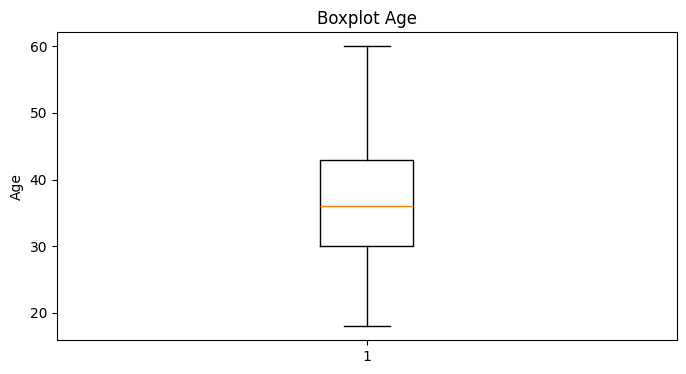

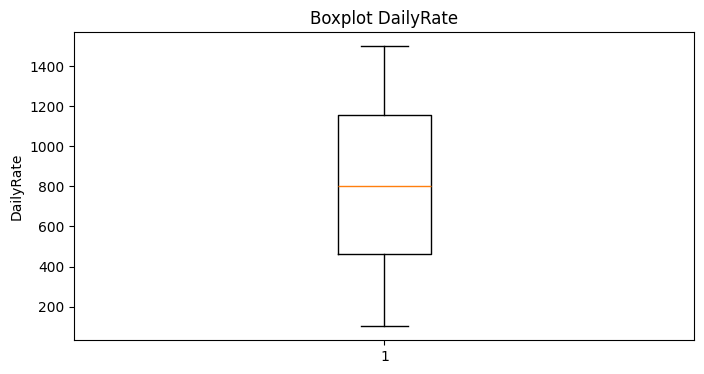

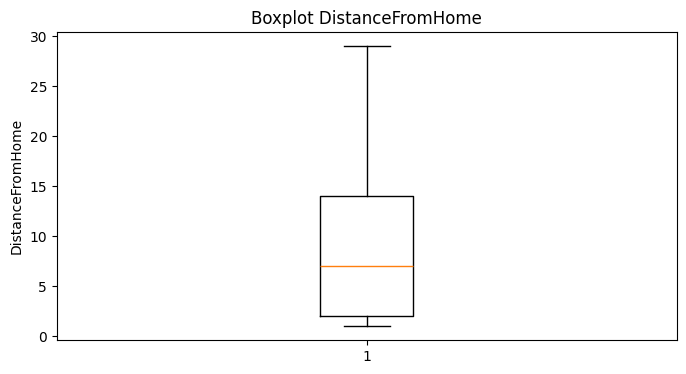

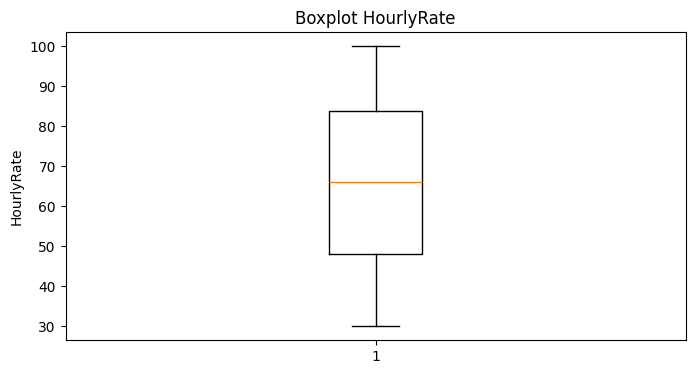

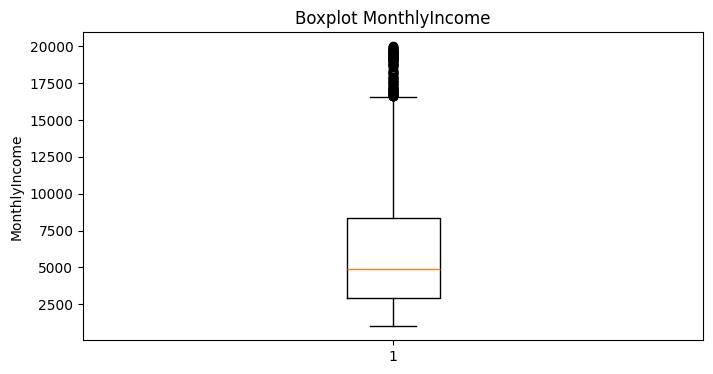

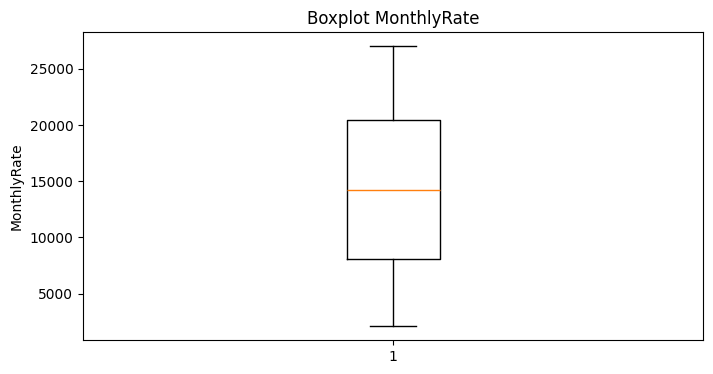

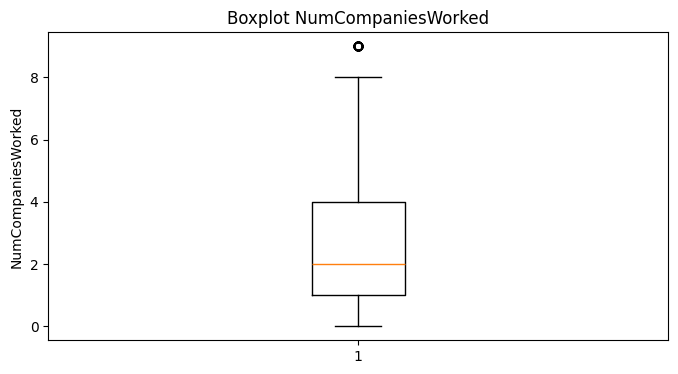

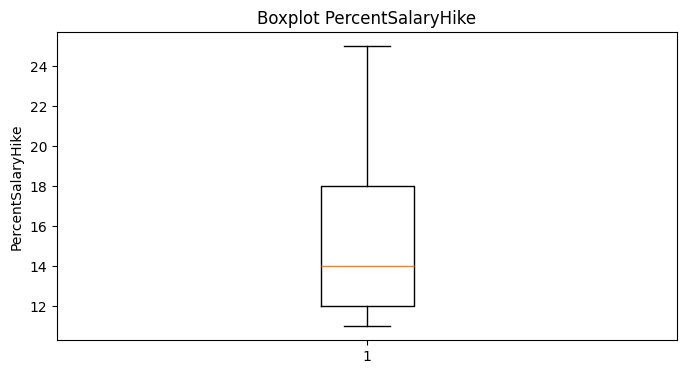

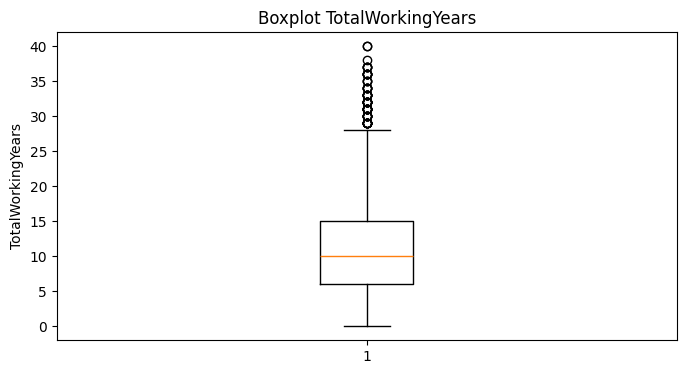

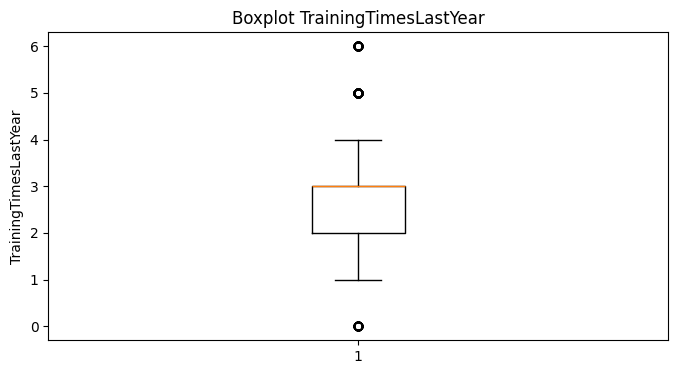

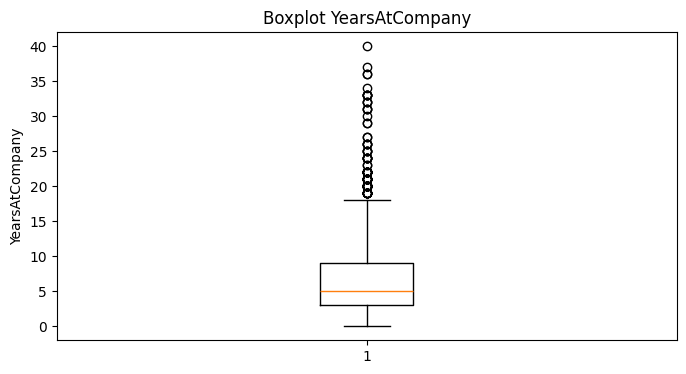

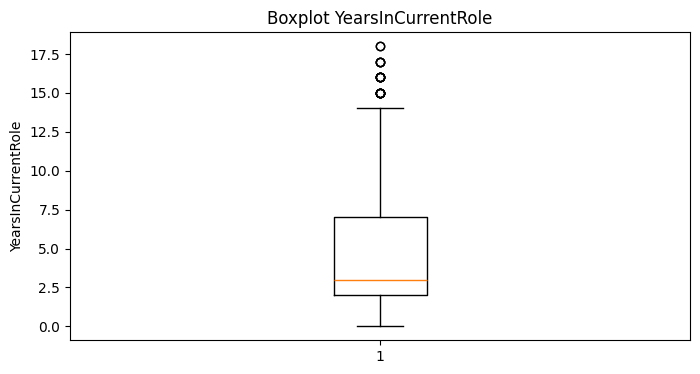

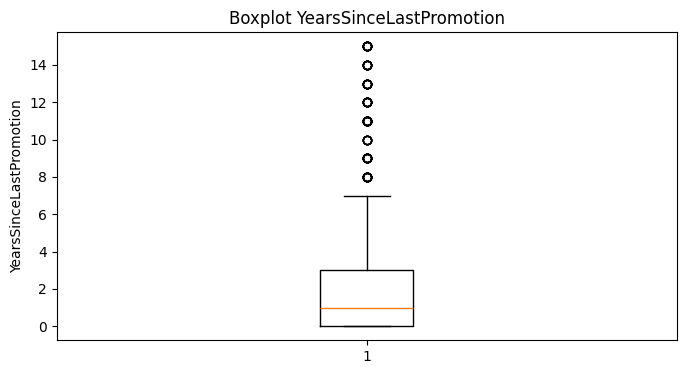

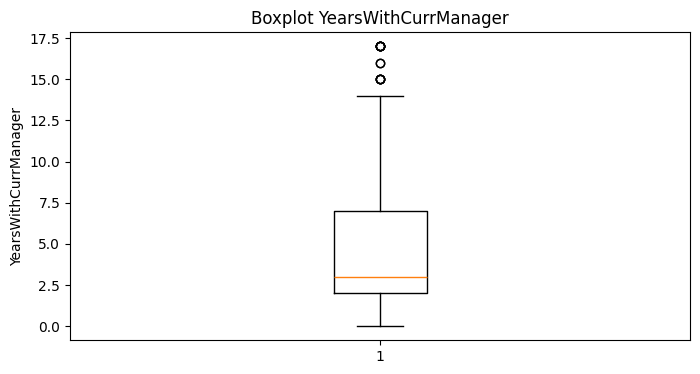

In [13]:
# Check outlier for numeric columns using boxplots
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    plt.boxplot(employee_df[col].dropna())
    plt.title(f"Boxplot {col}")
    plt.ylabel(col)
    plt.show()

## Data Preparation / Preprocessing

In [14]:
# Drop rows with missing values in the dataset
employee_df = employee_df.dropna(subset=["Attrition"])

In [15]:
# Check missing values after dropping rows with missing values
employee_df.isna().sum()

EmployeeId                  0
Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [16]:
# Export dataframe to CSV file
employee_df.to_csv("employee_data_cleaned.csv", index=False)

In [17]:
# Drop data not functional for analysis, such as 'EmployeeCount', 'EmployeeNumber', 'StandardHours', and 'Over18'
employee_df = employee_df.drop(
    columns=['EmployeeCount', 'EmployeeId', 'Over18', 'StandardHours']
)

## Modeling

In [18]:
# Siapkan fitur dan target
X = employee_df.drop(columns=["Attrition"])
y = employee_df["Attrition"].astype(int)


In [19]:
# Sisihkan validation set untuk pemilihan model/threshold; test hanya untuk evaluasi akhir
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)


In [20]:
# Deteksi fitur numerik (termasuk pandas nullable Int64) dan kategorikal
numeric_features = X_train.select_dtypes(include=["number"]).columns
categorical_features = X_train.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)


In [21]:
from sklearn.linear_model import LogisticRegression

lr = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])
lr.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['Age', 'DailyRate', 'DistanceFromHome', 'HourlyRate', 'MonthlyIncome',
       'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'YearsAtCompany',
       'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dt...
                                                  Index(['BusinessTravel', 'Department', 'Education', 'EducationField',
       'EnvironmentSatisfaction', 'Gender', 'JobInvolvement', 'JobLevel',
       'JobRole', 'JobSatisfaction', 'MaritalStatus', 'OverTime',
       'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel',
       'WorkLifeBalance'],
      dtype='object'))])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=2000,
                                    random_state=42))])

In [22]:
from sklearn.ensemble import RandomForestClassifier

rf = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=400,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])
rf.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['Age', 'DailyRate', 'DistanceFromHome', 'HourlyRate', 'MonthlyIncome',
       'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'YearsAtCompany',
       'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dt...
       'EnvironmentSatisfaction', 'Gender', 'JobInvolvement', 'JobLevel',
       'JobRole', 'JobSatisfaction', 'MaritalStatus', 'OverTime',
       'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel',
       'WorkLifeBalance'],
      dtype='object'))])),
                ('model',
                 RandomForestClassifier(class_weight='balanced_subsample',
                                        min_samples_leaf=2, n_estimators=400,
                                        n_jobs=-1, random_state=42))])

## Evaluation

In [23]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    precision_recall_curve,
    f1_score
)

# Bandingkan model dan pilih threshold hanya berdasarkan validation set
models = {"Logistic Regression": lr, "Random Forest": rf}
validation_results = {}

for model_name, candidate in models.items():
    positive_class_index = list(candidate.classes_).index(1)
    val_prob = candidate.predict_proba(X_val)[:, positive_class_index]
    precision, recall, thresholds = precision_recall_curve(y_val, val_prob)
    val_f1 = 2 * precision[:-1] * recall[:-1] / (
        precision[:-1] + recall[:-1] + 1e-12
    )
    best_index = val_f1.argmax()
    threshold = thresholds[best_index]
    val_pred = (val_prob >= threshold).astype(int)

    validation_results[model_name] = {
        "model": candidate,
        "threshold": threshold,
        "f1": f1_score(y_val, val_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_val, val_prob)
    }
    print(
        f"{model_name}: validation F1={validation_results[model_name]['f1']:.3f}, "
        f"ROC-AUC={validation_results[model_name]['roc_auc']:.3f}, "
        f"threshold={threshold:.3f}"
    )

# Pilih model berdasarkan F1 validation, lalu evaluasi sekali pada test set
best_name = max(validation_results, key=lambda name: validation_results[name]["f1"])
best_result = validation_results[best_name]
best_model = best_result["model"]
best_threshold = best_result["threshold"]

positive_class_index = list(best_model.classes_).index(1)
test_prob = best_model.predict_proba(X_test)[:, positive_class_index]
test_pred = (test_prob >= best_threshold).astype(int)

print(f"\nModel terpilih: {best_name}")
print(f"Threshold dari validation set: {best_threshold:.3f}")
print("\nClassification report pada test set:")
print(classification_report(y_test, test_pred, zero_division=0))
print("Confusion matrix:")
print(confusion_matrix(y_test, test_pred))
print("Test ROC-AUC:", roc_auc_score(y_test, test_prob))


Logistic Regression: validation F1=0.547, ROC-AUC=0.833, threshold=0.565
Random Forest: validation F1=0.543, ROC-AUC=0.828, threshold=0.262

Model terpilih: Logistic Regression
Threshold dari validation set: 0.565

Classification report pada test set:
              precision    recall  f1-score   support

           0       0.95      0.84      0.89       176
           1       0.50      0.78      0.61        36

    accuracy                           0.83       212
   macro avg       0.72      0.81      0.75       212
weighted avg       0.87      0.83      0.84       212

Confusion matrix:
[[148  28]
 [  8  28]]
Test ROC-AUC: 0.8513257575757576
